<a href="https://colab.research.google.com/github/lsd58/hw04/blob/Fall26/cee_4200_pset%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Defining The Parameters of Pine Creek Reservoir**


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
# x1 = town allocation; x2 = farm allocation
# Allocations in million m³; profit in million dollars

A = np.array([[ 1,  1],
              [ 1,  0],
              [ 0,  1],
              [-1,  0],
              [ 0, -1]])

b = np.array([[5],
              [3.5],
              [3],
              [-1],
              [-1]])

c = np.array([[0.10],
              [0.05]])


**Visualizing the boundaries and constraints**

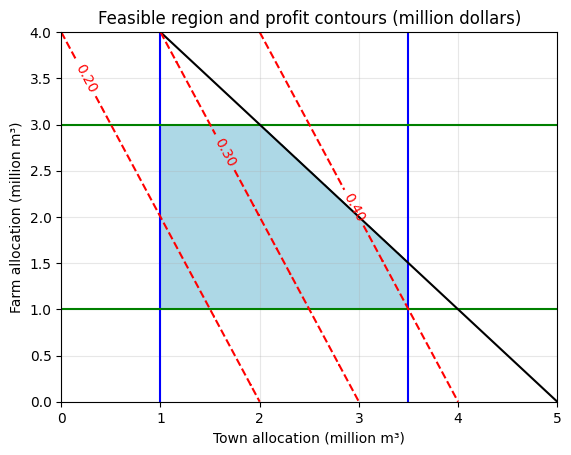

In [ ]:
x, y = np.meshgrid(np.linspace(0, 5, 501),
                   np.linspace(0, 4, 401))

allowed = ((x >= 1) & (x <= 3.5) &
           (y >= 1) & (y <= 3) &
           (x + y <= 5))

plt.contourf(x, y, allowed,
             levels=[0.5, 1.5], colors=["lightblue"])

plt.contour(x, y, x, levels=[1, 3.5], colors="blue")
plt.contour(x, y, y, levels=[1, 3], colors="green")
plt.contour(x, y, x + y, levels=[5], colors="black")

profit = 0.10*x + 0.05*y
lines = plt.contour(x, y, profit,
                    levels=[0.20, 0.30, 0.40],
                    colors="red", linestyles="dashed")
plt.clabel(lines, fmt="%.2f")

plt.xlabel("Town allocation (million m³)")
plt.ylabel("Farm allocation (million m³)")
plt.title("Feasible region and profit contours (million dollars)")
plt.grid(alpha=0.3)

**Solving the Linear Program**

In [ ]:
c_min = (-c).ravel()
A_ub = A
b_ub = b.ravel()

res = linprog(c_min, A_ub=A_ub, b_ub=b_ub,
              bounds=[(0, None), (0, None)],
              method="highs")

if res.success:
    x1, x2 = res.x
    z = c.ravel() @ res.x

    print(f"Town allocation: {x1:.2f} million m³")
    print(f"Farm allocation: {x2:.2f} million m³")
    print(f"Maximum profit: ${z * 1_000_000:,.2f}")
    print(f"Status: {res.message}")

else:
    print("Solver failed:", res.message)

Town allocation: 3.50 million m³
Farm allocation: 1.50 million m³
Maximum profit: $425,000.00
Status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
